In [3]:
# ============================================================
# Project A: House Price Prediction (Linear Regression)
# ============================================================

# Phase 1: Data Preparation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
house_df = pd.read_csv("C:/Users/krishna/Downloads/archive (2)/Housing.csv")   # Replace with actual Kaggle path

# Inspect data
print(house_df.info())
print(house_df.describe())

# Handle missing values
house_df.fillna(house_df.median(numeric_only=True), inplace=True)

# Encode categorical variables
house_df = pd.get_dummies(house_df, drop_first=True)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB
None
              price          area    bedrooms   bathrooms     stories  \
count  5.450000e+02    545.000000  545.000000  545.000000  545.000000   
mea

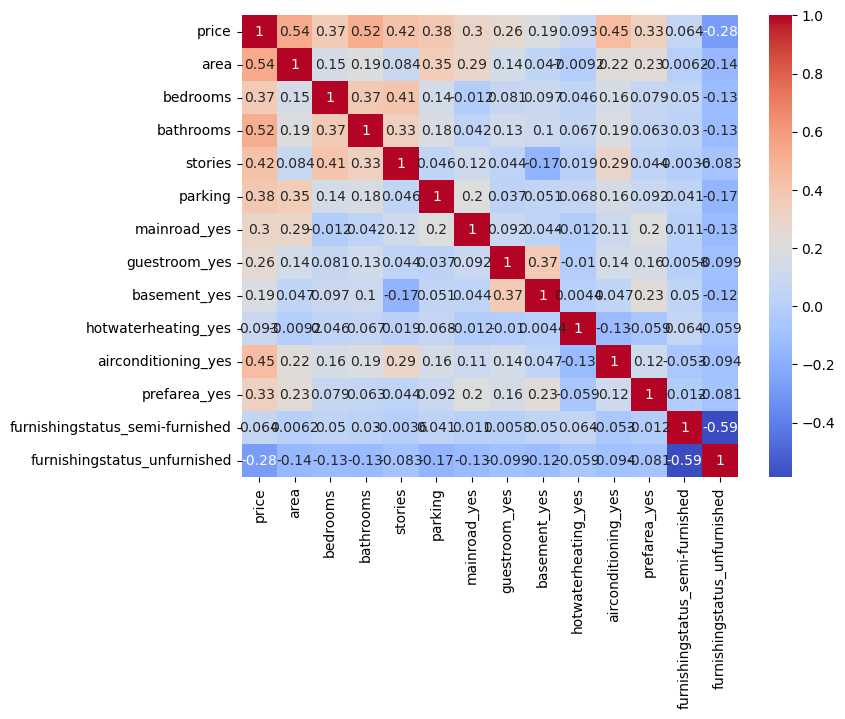

In [4]:
# Phase 2: Feature Engineering & Selection
# Correlation matrix
plt.figure(figsize=(8,6))
sns.heatmap(house_df.corr(), annot=True, cmap="coolwarm")
plt.show()


In [5]:
# Phase 3: Linear Regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X = house_df.drop("price", axis=1)
y = house_df["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

linreg = LinearRegression()
linreg.fit(X_train, y_train)

y_pred = linreg.predict(X_test)


RMSE: 1324506.9600914388
R2 Score: 0.6529242642153182


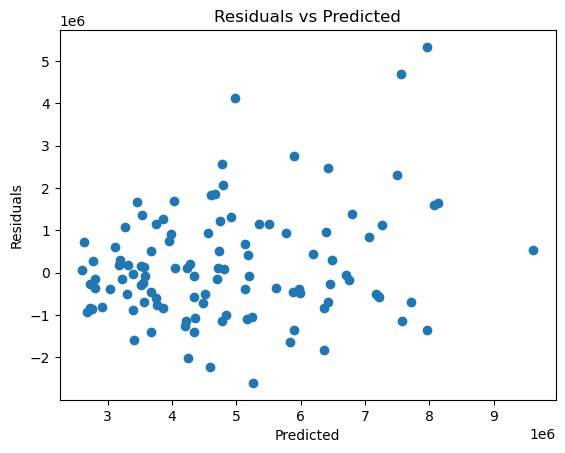

In [6]:
# Phase 4: Evaluation
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

# Residuals plot
plt.scatter(y_pred, y_test - y_pred)
plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted")
plt.show()


In [7]:
# Phase 5: Hyperparameter Tuning (Ridge/Lasso)
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV

ridge = Ridge()
params = {"alpha":[0.1,1,10,100]}
ridge_cv = GridSearchCV(ridge, params, cv=5)
ridge_cv.fit(X_train, y_train)
print("Best Ridge alpha:", ridge_cv.best_params_)

lasso = Lasso()
params = {"alpha":[0.001,0.01,0.1,1]}
lasso_cv = GridSearchCV(lasso, params, cv=5)
lasso_cv.fit(X_train, y_train)
print("Best Lasso alpha:", lasso_cv.best_params_)


Best Ridge alpha: {'alpha': 10}
Best Lasso alpha: {'alpha': 1}
